In [278]:
import astroML 
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii
from astropy.stats import bayesian_blocks
from astropy.table import Table
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii
from pylab import *
from astropy.io import fits
from scipy import stats
from astropy import units as u
import matplotlib
from matplotlib.ticker import FixedLocator
from astropy.stats import bayesian_blocks
import pandas as pd
import seaborn as sns
from astropy import units
from scipy.optimize import curve_fit
import matplotlib.ticker as ticker
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from astropy.table import Table
from matplotlib.ticker import FormatStrFormatter
from astropy.cosmology import FlatLambdaCDM
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)


In [314]:
data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB060522/grb_avg2.lc')[1].data
data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB060927/grb_avg2.lc')[1].data
data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB080913/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB090423/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB090429B/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB090709A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB100905A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB120521C/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB120923A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB130606A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB131227A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB140304A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB201221A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB210905A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB220521A/grb_avg2.lc')[1].data
# data=fits.open('/home/mittu/GRB140304A/BAT_all/GRB240218A/grb_avg2.lc')[1].data

data = Table([data['TIME'],data['RATE'],data['ERROR']])
data = data[data['col0']<100]
data = data[data['col0']>-10] 
a, b, c = data['col0'],data['col1'],data['col2']

In [315]:
# grb_table = grb_table[grb_table['col0']<200]
# grb_table = grb_table[grb_table['col0']>-20]
# grb_table
# a = np.array(grb_table['col0'])
# b = np.array(grb_table['col1'])
# c = np.array(grb_table['col2'])

(-0.02, 0.25)

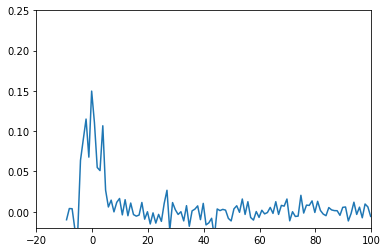

In [316]:
plt.plot(a,b)
plt.xlim(-20,100)
plt.ylim(-0.02, 0.25)

In [317]:
edges = bayesian_blocks(a, b, sigma=c/2, fitness='measures', p0=0.01)

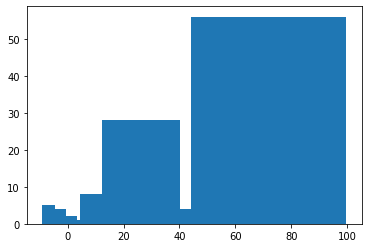

In [318]:
freq, bins, _ = plt.hist(a, bins=edges)

(-0.02, 0.5)

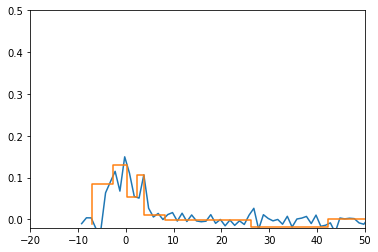

In [319]:
t = []
f = []
for le, re in zip(edges[:-1], edges[1:]):
    idx = (le <= a) & (a < re)
    tf = np.mean(b[idx])
    t.append(0.5*(le+re))
    f.append(tf)

plt.plot(a, b)
plt.step(t, f)
plt.xlim(-20,50)
plt.ylim(-0.02, 0.5)

In [320]:
y = (edges[1:]-edges[:-1])/2

In [321]:
np.min(y)

0.5

In [322]:
10.3*86400

889920.0000000001